<a href="https://colab.research.google.com/github/tharunikaravi028/SolarScope_AI/blob/main/Solarscope.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Chat model: nova-micro
Embedding size: 1536
['overheating_and_hotspots.txt', 'inspection_and_maintenance_checklist.txt', 'dust_soiling_maintenance.txt', 'pv_degradation_guide.txt']
Total chunks: 8
Embeddings shape: (8, 1536)


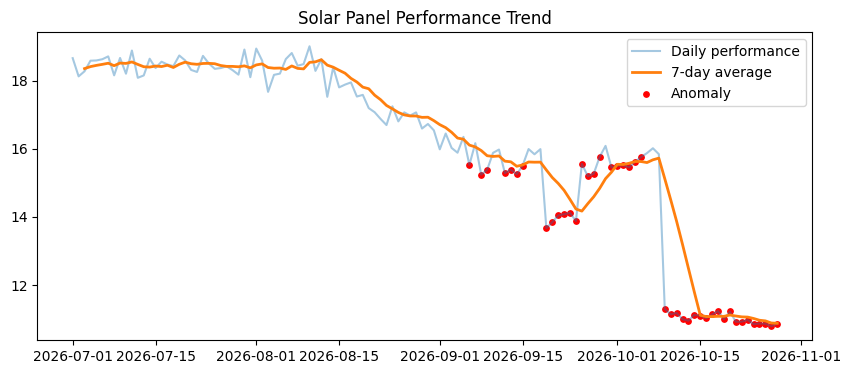

- 43 days with performance more than 15% below baseline
- Panel temperature above 65C on 6 days (2026-09-19 to 2026-09-24): possible overheating
- Sudden performance drop of 29% on 2026-10-09: possible panel or wiring damage
- Overall performance is 41% below the initial baseline: possible dust accumulation or degradation
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://900b3b31f5d21b5832.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================================
# SolarScope AI
# Intelligent Solar Panel Performance Monitoring and
# Degradation Analysis Using Advanced RAG
#
# Platform : Google Colab
# Models   : nova-micro (LLM), text-embedding-3-small (embeddings)
# Pipeline : Upload CSV -> Anomaly detection -> Query rewriting ->
#            Hybrid retrieval (semantic + BM25) -> Rank fusion ->
#            LLM report with citations -> Gradio web app
#
# SINGLE-CELL VERSION: paste everything into ONE Colab cell and run it.
# ============================================================


# ---------- Step 1: Install libraries ----------
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "openai", "rank_bm25", "pypdf", "pandas", "matplotlib", "gradio"], check=True)


# ---------- Step 2: Connect to the company API ----------
# Add API_KEY and BASE_URL in Colab Secrets (key icon) and enable notebook access.
from google.colab import userdata
from openai import OpenAI

client = OpenAI(api_key=userdata.get("API_KEY"), base_url=userdata.get("BASE_URL"))

MODEL = "nova-micro"                    # chat model (query rewriting + report)
EMBED_MODEL = "text-embedding-3-small"  # embedding model
print("Chat model:", MODEL)

# Quick connection test
e = client.embeddings.create(model=EMBED_MODEL, input=["solar panel overheating"])
print("Embedding size:", len(e.data[0].embedding))   # expect 1536


# ---------- Step 3: Knowledge base (documents) ----------
import os
os.makedirs("/content/docs", exist_ok=True)

docs = {
"pv_degradation_guide.txt": """Solar panel degradation guide.
Photovoltaic modules lose output gradually over their life. A typical long-term degradation rate for crystalline silicon panels is about 0.5 percent per year, and a rate above roughly 1 percent per year suggests a problem.
Common causes of faster degradation: potential induced degradation (PID), light induced degradation in the first months, encapsulant browning, delamination, corrosion of cell contacts, and microcracks in cells.
A sudden drop in power output is usually not normal ageing. It points to a fault such as a failed bypass diode, a broken connector, a cracked module, or a string failure. Inspect the module and the string wiring first.""",

"overheating_and_hotspots.txt": """Overheating and hot spots in solar panels.
Panel output falls as cell temperature rises. Most crystalline silicon modules have a temperature coefficient of power between minus 0.3 and minus 0.5 percent per degree Celsius above 25 degrees Celsius. A panel at 65 degrees Celsius can lose around 12 to 20 percent of its rated power from heat alone.
Hot spots happen when a cell or group of cells dissipates power as heat, usually because of partial shading, cell mismatch, cracked cells, or a failed bypass diode. Local temperatures can rise far above the rest of the module and damage the encapsulant.
Detection: infrared thermography shows hot spots clearly. A temperature difference of more than 10 to 20 degrees Celsius between cells in the same module needs attention.
Prevention: keep ventilation gaps behind the panels, remove shading from vegetation or objects, replace damaged modules, and check bypass diodes during maintenance.""",

"dust_soiling_maintenance.txt": """Dust and soiling losses.
Dust, pollen, bird droppings, and sand settle on the glass and block sunlight. Soiling typically causes a few percent energy loss in normal conditions, and much more in dry, dusty regions or near construction and farmland, especially when there is no rain for weeks.
Signs of soiling: output declines slowly over days or weeks while irradiance stays similar, and performance recovers after rain or cleaning.
Cleaning guidance: clean early in the morning or in the evening when panels are cool. Use soft brushes or low pressure water. Avoid abrasive tools and cold water on very hot glass. Do not walk on panels.
Cleaning frequency should depend on measured losses. Track the performance ratio and schedule cleaning when the drop from soiling becomes larger than the cost of cleaning.""",

"inspection_and_maintenance_checklist.txt": """Routine inspection and maintenance checklist for solar plants.
Monthly: visual check for dirt, cracks, discoloured cells, snail trails, and loose frames. Check that no shade has appeared from new vegetation or structures.
Quarterly: inspect cabling, connectors, and junction boxes for corrosion, heat marks, or loose connections. Compare string currents to find underperforming strings.
Yearly: infrared thermography scan, insulation resistance test, inverter check, and mounting structure inspection.
Monitoring: calculate the performance ratio, which is actual energy output divided by the expected energy from irradiance. A steady performance ratio between about 75 and 85 percent is healthy. A fall of more than 5 to 10 percent from the normal baseline should trigger an inspection.
Record all findings in a maintenance log so that degradation trends can be tracked over the years."""
}

for name, text in docs.items():
    with open(f"/content/docs/{name}", "w") as f:
        f.write(text)
print(os.listdir("/content/docs"))
# Optional: upload real PDFs into /content/docs, then re-run the next cell.


# ---------- Step 4: Load, chunk and embed the documents ----------
import glob
import numpy as np
from pypdf import PdfReader


def load_docs(folder="/content/docs"):
    out = []
    for f in glob.glob(folder + "/*"):
        name = os.path.basename(f)
        if f.endswith(".pdf"):
            for i, p in enumerate(PdfReader(f).pages):
                out.append((name, i + 1, p.extract_text() or ""))
        elif f.endswith(".txt"):
            out.append((name, 1, open(f).read()))
    return out


def chunk(text, size=800, overlap=150):
    return [text[i:i + size] for i in range(0, len(text), size - overlap) if text[i:i + size].strip()]


chunks = []
for src, page, text in load_docs():
    for c in chunk(text):
        chunks.append({"text": c, "source": src, "page": page})
print("Total chunks:", len(chunks))

vectors = []
for i in range(0, len(chunks), 50):
    batch = [c["text"] for c in chunks[i:i + 50]]
    res = client.embeddings.create(model=EMBED_MODEL, input=batch)
    vectors += [d.embedding for d in res.data]

emb = np.array(vectors, dtype="float32")
emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)
print("Embeddings shape:", emb.shape)


# ---------- Step 5: Advanced RAG (query rewriting + hybrid search + rank fusion) ----------
from rank_bm25 import BM25Okapi

bm25 = BM25Okapi([c["text"].lower().split() for c in chunks])


def rewrite_query(q):
    """Use the LLM to turn one question into 3 better search queries."""
    r = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": "Rewrite the user's question as 3 short search queries for solar panel technical documents. Output one query per line, no numbering."},
            {"role": "user", "content": q}
        ],
        max_tokens=100
    )
    lines = [x.strip("-• ").strip() for x in r.choices[0].message.content.split("\n") if x.strip()]
    return lines[:3] + [q]


def hybrid_retrieve(q, k=4):
    """Semantic (embeddings) + keyword (BM25) search merged with reciprocal rank fusion."""
    scores = {}
    for query in rewrite_query(q):
        # semantic search
        qe = np.array(client.embeddings.create(model=EMBED_MODEL, input=[query]).data[0].embedding, dtype="float32")
        qe = qe / np.linalg.norm(qe)
        sem = emb @ qe
        for rank, i in enumerate(np.argsort(sem)[::-1][:6]):
            scores[i] = scores.get(i, 0) + 1 / (60 + rank)
        # keyword search
        kw = bm25.get_scores(query.lower().split())
        for rank, i in enumerate(np.argsort(kw)[::-1][:6]):
            scores[i] = scores.get(i, 0) + 1 / (60 + rank)
    top = sorted(scores, key=scores.get, reverse=True)[:k]
    return [chunks[i] for i in top]


# ---------- Step 6: Create sample solar data (synthetic, with 3 built-in problems) ----------
import pandas as pd

np.random.seed(42)
n = 120
dates = pd.date_range("2026-07-01", periods=n)
irr = np.random.uniform(5, 7, n)                        # daily irradiance
temp = 40 + (irr - 5) * 5 + np.random.normal(0, 2, n)   # panel temperature
temp[80:86] += 25                                       # overheating period

health = np.ones(n)
health[40:70] = np.linspace(1, 0.85, 30)                # slow dust build-up
health[70:100] = 0.85
health[100:] = 0.60                                     # sudden damage

power = irr * 20 * (1 - 0.004 * (temp - 25)) * health + np.random.normal(0, 0.3, n)

df = pd.DataFrame({"date": dates, "irradiance": irr.round(2),
                   "panel_temp": temp.round(1), "power_output": power.round(2)})
df.to_csv("/content/solar_data.csv", index=False)
df.head()


# ---------- Step 7: Performance analysis (anomaly detection + chart) ----------
import matplotlib.pyplot as plt


def analyze(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df["pr"] = df["power_output"] / df["irradiance"]            # performance ratio proxy
    df["pr_roll"] = df["pr"].rolling(7, min_periods=3).mean()

    baseline = df["pr"].iloc[:20].median()
    df["anomaly"] = df["pr"] < baseline * 0.85
    findings = []

    n_anom = int(df["anomaly"].sum())
    if n_anom:
        findings.append(f"{n_anom} days with performance more than 15% below baseline")

    hot = df["panel_temp"] > 65
    if hot.sum() >= 2:
        findings.append(f"Panel temperature above 65C on {int(hot.sum())} days "
                        f"({df[hot]['date'].iloc[0].date()} to {df[hot]['date'].iloc[-1].date()}): possible overheating")

    prev_avg = df["pr"].rolling(5).mean().shift(1)
    change = df["pr"] / prev_avg - 1
    if change.min() < -0.2:
        d = df.loc[change.idxmin(), "date"].date()
        findings.append(f"Sudden performance drop of {abs(change.min()):.0%} on {d}: possible panel or wiring damage")

    decline = 1 - df["pr"].iloc[-14:].mean() / baseline
    if decline > 0.05:
        findings.append(f"Overall performance is {decline:.0%} below the initial baseline: possible dust accumulation or degradation")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(df["date"], df["pr"], alpha=0.4, label="Daily performance")
    ax.plot(df["date"], df["pr_roll"], linewidth=2, label="7-day average")
    ax.scatter(df[df.anomaly]["date"], df[df.anomaly]["pr"], c="red", s=15, label="Anomaly")
    ax.set_title("Solar Panel Performance Trend")
    ax.legend()
    fig.savefig("/content/trend.png", bbox_inches="tight")
    plt.show()
    return df, findings


df = pd.read_csv("/content/solar_data.csv")
result_df, findings = analyze(df)
for f in findings:
    print("-", f)


# ---------- Step 8: AI report generation (RAG + LLM) ----------
def generate_report(df, inspection_notes=""):
    df, findings = analyze(df)

    # Retrieve supporting document passages for each finding
    refs, seen = [], set()
    for f in findings:
        for c in hybrid_retrieve(f + " causes and maintenance", k=2):
            key = (c["source"], c["text"][:50])
            if key not in seen:
                seen.add(key)
                refs.append(c)

    context = "\n\n".join(f"[{c['source']}] {c['text']}" for c in refs[:6])
    stats = (f"Average irradiance: {df['irradiance'].mean():.2f}, "
             f"average panel temperature: {df['panel_temp'].mean():.1f}C, "
             f"max panel temperature: {df['panel_temp'].max():.1f}C, "
             f"average power output: {df['power_output'].mean():.2f}")

    prompt = f"""You are a solar panel operations and maintenance expert.
Write a detailed report with these sections:
1. Performance Summary
2. Detected Issues
3. Possible Causes
4. Maintenance Suggestions
5. References

Rules: use ONLY the context below for technical claims, and cite sources like [filename].
In the References section, list the source file names you used.

Detected findings:
{chr(10).join('- ' + f for f in findings)}

Data statistics: {stats}
Inspection notes: {inspection_notes or 'None provided'}

Context from technical documents:
{context}"""

    r = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        max_tokens=1200
    )
    return r.choices[0].message.content


# ---------- Step 9: Retrieval evaluation (hit rate) ----------
RUN_EVAL = False   # set True to measure retrieval hit rate (slower)
if RUN_EVAL:
    tests = [
        ("Why is output dropping slowly over weeks?", "dust_soiling_maintenance.txt"),
        ("What causes hot spots and high panel temperature?", "overheating_and_hotspots.txt"),
        ("What does a sudden drop in power output mean?", "pv_degradation_guide.txt"),
        ("How often should inspection and maintenance be done?", "inspection_and_maintenance_checklist.txt"),
        ("How should solar panels be cleaned?", "dust_soiling_maintenance.txt"),
    ]

    hits = 0
    for q, expected in tests:
        got = [c["source"] for c in hybrid_retrieve(q, k=2)]
        ok = expected in got
        hits += ok
        print("OK  " if ok else "MISS", q, "->", got)
    print(f"\nRetrieval Hit Rate@2: {hits}/{len(tests)} = {hits / len(tests):.0%}")


# ---------- Step 10: Gradio web application ----------
import gradio as gr


def full_analysis(csv_file, notes):
    if csv_file is None:
        return "Please upload a CSV file.", None, "", "", "", None
    path = csv_file if isinstance(csv_file, str) else csv_file.name
    try:
        data = pd.read_csv(path)
        needed = {"date", "irradiance", "panel_temp", "power_output"}
        if not needed.issubset(data.columns):
            return f"CSV must contain: {sorted(needed)}", None, "", "", "", None

        d, findings = analyze(data)
        baseline = d["pr"].iloc[:20].median()
        decline = 1 - d["pr"].iloc[-14:].mean() / baseline
        status = "🔴 CRITICAL" if decline > 0.25 else "🟡 WARNING" if decline > 0.10 else "🟢 HEALTHY"

        status_md = (f"## System status: {status}\n\n"
                     f"| Metric | Value |\n|---|---|\n"
                     f"| Performance vs baseline | -{decline:.0%} |\n"
                     f"| Anomalous days | {int(d['anomaly'].sum())} of {len(d)} |\n"
                     f"| Max panel temperature | {d['panel_temp'].max():.1f} °C |\n"
                     f"| Average irradiance | {d['irradiance'].mean():.2f} |")

        findings_md = "\n".join(f"- {f}" for f in findings) or "- No significant issues detected."

        evidence = hybrid_retrieve(" ".join(findings) or "normal solar performance", k=4)
        evidence_md = "\n\n".join(
            f"**Source: {c['source']}** (page {c['page']})\n\n> {c['text'][:350]}..." for c in evidence)

        report = generate_report(data, notes or "")
        with open("/content/solarscope_report.md", "w") as f:
            f.write(f"# SolarScope AI Report\n\n{status_md}\n\n## Findings\n{findings_md}\n\n{report}")

        return status_md, "/content/trend.png", findings_md, evidence_md, report, "/content/solarscope_report.md"
    except Exception as e:
        return f"Error: {e}", None, "", "", "", None


with gr.Blocks(title="SolarScope AI") as app:
    gr.Markdown("# ☀️ SolarScope AI\nIntelligent solar panel performance monitoring and degradation analysis using Advanced RAG")
    with gr.Row():
        with gr.Column(scale=1):
            f_in = gr.File(label="Performance CSV (date, irradiance, panel_temp, power_output)", file_types=[".csv"])
            notes_in = gr.Textbox(label="Inspection notes (optional)", lines=4,
                                  placeholder="e.g. Visible dust on panels, discoloured junction box")
            btn = gr.Button("Analyze", variant="primary")
        with gr.Column(scale=2):
            status_out = gr.Markdown()
            chart_out = gr.Image(label="Performance trend")
    with gr.Tabs():
        with gr.Tab("AI Report"):
            report_out = gr.Markdown()
        with gr.Tab("Detected Findings"):
            findings_out = gr.Markdown()
        with gr.Tab("Retrieved Evidence (RAG)"):
            evidence_out = gr.Markdown()
    dl = gr.File(label="Download report")
    btn.click(full_analysis, [f_in, notes_in],
              [status_out, chart_out, findings_out, evidence_out, report_out, dl])

app.launch(share=True, debug=False)

In [ ]:
# ============================================================
# SolarScope AI  -  MULTI-AGENT VERSION
# Intelligent Solar Panel Performance Monitoring and
# Degradation Analysis Using Advanced RAG + Multi-Agent System
#
# Platform : Google Colab (paste into ONE cell and run)
# Models   : nova-micro (LLM), text-embedding-3-small (embeddings)
# Secrets  : API_KEY and BASE_URL in Colab Secrets (notebook access ON)
#
# AGENTS (each has one job, they share a "state" and a "trace"):
#   1. Data Analyst Agent        - finds anomalies in the CSV (rule-based)
#   2. Inspection Notes Agent    - turns inspection text into observations (LLM)
#   3. Retrieval Agent           - Advanced RAG: query rewriting + hybrid search
#   4. Diagnosis Agent           - explains likely cause of each finding (LLM)
#   5. Maintenance Planner Agent - builds a prioritised action plan (LLM)
#   6. Report Writer Agent       - writes the final cited report (LLM)
#   7. Reviewer Agent            - checks citations/sections, asks writer to fix
#   Orchestrator                 - runs the agents in order and logs everything
# ============================================================


# ---------- Step 1: Install libraries ----------
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "openai", "rank_bm25", "pypdf", "pandas", "matplotlib", "gradio"], check=True)


# ---------- Step 2: Imports and API connection ----------
import os, re, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata
from openai import OpenAI
from pypdf import PdfReader
from rank_bm25 import BM25Okapi
import gradio as gr

client = OpenAI(api_key=userdata.get("API_KEY"), base_url=userdata.get("BASE_URL"))
MODEL = "nova-micro"                    # chat model used by all LLM agents
EMBED_MODEL = "text-embedding-3-small"  # embedding model for retrieval


def llm(system, user, max_tokens=700):
    """One LLM call with a simple retry (used by every LLM agent)."""
    for attempt in range(3):
        try:
            r = client.chat.completions.create(
                model=MODEL,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}],
                max_tokens=max_tokens)
            return r.choices[0].message.content.strip()
        except Exception:
            if attempt == 2:
                raise
            time.sleep(2)


def embed(texts):
    """Embed a list of texts and return normalised vectors."""
    vectors = []
    for i in range(0, len(texts), 50):
        res = client.embeddings.create(model=EMBED_MODEL, input=texts[i:i + 50])
        vectors += [d.embedding for d in res.data]
    v = np.array(vectors, dtype="float32")
    return v / np.linalg.norm(v, axis=1, keepdims=True)


e = embed(["solar panel overheating"])
print("API connected. Embedding size:", e.shape[1])   # expect 1536


# ---------- Step 3: Knowledge base documents ----------
os.makedirs("/content/docs", exist_ok=True)

docs = {
"pv_degradation_guide.txt": """Solar panel degradation guide.
Photovoltaic modules lose output gradually over their life. A typical long-term degradation rate for crystalline silicon panels is about 0.5 percent per year, and a rate above roughly 1 percent per year suggests a problem.
Common causes of faster degradation: potential induced degradation (PID), light induced degradation in the first months, encapsulant browning, delamination, corrosion of cell contacts, and microcracks in cells.
A sudden drop in power output is usually not normal ageing. It points to a fault such as a failed bypass diode, a broken connector, a cracked module, or a string failure. Inspect the module and the string wiring first.""",

"overheating_and_hotspots.txt": """Overheating and hot spots in solar panels.
Panel output falls as cell temperature rises. Most crystalline silicon modules have a temperature coefficient of power between minus 0.3 and minus 0.5 percent per degree Celsius above 25 degrees Celsius. A panel at 65 degrees Celsius can lose around 12 to 20 percent of its rated power from heat alone.
Hot spots happen when a cell or group of cells dissipates power as heat, usually because of partial shading, cell mismatch, cracked cells, or a failed bypass diode. Local temperatures can rise far above the rest of the module and damage the encapsulant.
Detection: infrared thermography shows hot spots clearly. A temperature difference of more than 10 to 20 degrees Celsius between cells in the same module needs attention.
Prevention: keep ventilation gaps behind the panels, remove shading from vegetation or objects, replace damaged modules, and check bypass diodes during maintenance.""",

"dust_soiling_maintenance.txt": """Dust and soiling losses.
Dust, pollen, bird droppings, and sand settle on the glass and block sunlight. Soiling typically causes a few percent energy loss in normal conditions, and much more in dry, dusty regions or near construction and farmland, especially when there is no rain for weeks.
Signs of soiling: output declines slowly over days or weeks while irradiance stays similar, and performance recovers after rain or cleaning.
Cleaning guidance: clean early in the morning or in the evening when panels are cool. Use soft brushes or low pressure water. Avoid abrasive tools and cold water on very hot glass. Do not walk on panels.
Cleaning frequency should depend on measured losses. Track the performance ratio and schedule cleaning when the drop from soiling becomes larger than the cost of cleaning.""",

"inspection_and_maintenance_checklist.txt": """Routine inspection and maintenance checklist for solar plants.
Monthly: visual check for dirt, cracks, discoloured cells, snail trails, and loose frames. Check that no shade has appeared from new vegetation or structures.
Quarterly: inspect cabling, connectors, and junction boxes for corrosion, heat marks, or loose connections. Compare string currents to find underperforming strings.
Yearly: infrared thermography scan, insulation resistance test, inverter check, and mounting structure inspection.
Monitoring: calculate the performance ratio, which is actual energy output divided by the expected energy from irradiance. A steady performance ratio between about 75 and 85 percent is healthy. A fall of more than 5 to 10 percent from the normal baseline should trigger an inspection.
Record all findings in a maintenance log so that degradation trends can be tracked over the years."""
}

for name, text in docs.items():
    with open(f"/content/docs/{name}", "w") as f:
        f.write(text)
# Optional: upload real PDFs into /content/docs BEFORE running this program.


# ---------- Step 4: Knowledge base with Advanced RAG search ----------
class KnowledgeBase:
    """Indexes documents and offers hybrid search (semantic + BM25 + rank fusion)."""

    def __init__(self, folder="/content/docs"):
        self.folder = folder
        self.chunks = []

    @staticmethod
    def _chunk(text, size=800, overlap=150):
        return [text[i:i + size] for i in range(0, len(text), size - overlap)
                if text[i:i + size].strip()]

    def build(self):
        for f in glob.glob(self.folder + "/*"):
            name = os.path.basename(f)
            if f.endswith(".pdf"):
                pages = [(i + 1, p.extract_text() or "") for i, p in enumerate(PdfReader(f).pages)]
            elif f.endswith(".txt"):
                pages = [(1, open(f).read())]
            else:
                continue
            for page, text in pages:
                for c in self._chunk(text):
                    self.chunks.append({"text": c, "source": name, "page": page})
        self.emb = embed([c["text"] for c in self.chunks])
        self.bm25 = BM25Okapi([c["text"].lower().split() for c in self.chunks])
        print(f"Knowledge base ready: {len(self.chunks)} chunks from "
              f"{len(set(c['source'] for c in self.chunks))} documents")

    def rewrite(self, q):
        """Query rewriting: one question -> 3 better search queries."""
        out = llm("Rewrite the user's question as 3 short search queries for solar panel "
                  "technical documents. Output one query per line, no numbering.", q, max_tokens=100)
        lines = [x.strip("-• ").strip() for x in out.split("\n") if x.strip()]
        return lines[:3] + [q]

    def search(self, q, k=3):
        """Hybrid retrieval: semantic + keyword, merged with reciprocal rank fusion."""
        scores = {}
        for query in self.rewrite(q):
            qe = embed([query])[0]
            for rank, i in enumerate(np.argsort(self.emb @ qe)[::-1][:6]):
                scores[i] = scores.get(i, 0) + 1 / (60 + rank)
            kw = self.bm25.get_scores(query.lower().split())
            for rank, i in enumerate(np.argsort(kw)[::-1][:6]):
                scores[i] = scores.get(i, 0) + 1 / (60 + rank)
        top = sorted(scores, key=scores.get, reverse=True)[:k]
        return [self.chunks[i] for i in top]


kb = KnowledgeBase()
kb.build()


# ---------- Step 5: Sample data (synthetic) ----------
def make_sample_data():
    """unhealthy_data: dust loss + overheating + sudden damage.  healthy_data: normal."""
    np.random.seed(42)
    n = 120
    irr = np.random.uniform(5, 7, n)
    temp = 40 + (irr - 5) * 5 + np.random.normal(0, 2, n)
    temp[80:86] += 25                                        # overheating period
    health = np.ones(n)
    health[40:70] = np.linspace(1, 0.85, 30)                 # slow dust build-up
    health[70:100] = 0.85
    health[100:] = 0.60                                      # sudden damage
    power = irr * 20 * (1 - 0.004 * (temp - 25)) * health + np.random.normal(0, 0.3, n)
    pd.DataFrame({"date": pd.date_range("2026-07-01", periods=n).strftime("%Y-%m-%d"),
                  "irradiance": irr.round(2), "panel_temp": temp.round(1),
                  "power_output": power.round(2)}).to_csv("/content/solar_data.csv", index=False)

    np.random.seed(7)
    n = 60
    irr = np.random.uniform(5, 7, n)
    temp = 38 + (irr - 5) * 4 + np.random.normal(0, 2, n)
    power = irr * 20 * (1 - 0.004 * (temp - 25)) + np.random.normal(0, 0.3, n)
    pd.DataFrame({"date": pd.date_range("2026-09-01", periods=n).strftime("%Y-%m-%d"),
                  "irradiance": irr.round(2), "panel_temp": temp.round(1),
                  "power_output": power.round(2)}).to_csv("/content/healthy_data.csv", index=False)


make_sample_data()
print("Sample data saved: /content/solar_data.csv and /content/healthy_data.csv")


# ---------- Step 6: Shared trace and agent base class ----------
class Trace:
    """Records what every agent did (shown in the 'Agent Activity' tab)."""

    def __init__(self):
        self.t0 = time.time()
        self.events = []

    def log(self, agent, msg):
        self.events.append((time.time() - self.t0, agent, msg))

    def markdown(self):
        rows = "\n".join(f"| {t:5.1f}s | **{a}** | {m} |" for t, a, m in self.events)
        return "| Time | Agent | Action |\n|---|---|---|\n" + rows


class Agent:
    name = "Agent"

    def __init__(self, trace):
        self.trace = trace

    def say(self, msg):
        self.trace.log(self.name, msg)


# ---------- Step 7: The agents ----------
class DataAnalystAgent(Agent):
    """Agent 1: rule-based analysis of the performance CSV."""
    name = "Data Analyst Agent"

    def run(self, state):
        df = state["df"].copy()
        df["date"] = pd.to_datetime(df["date"])
        irr = df["irradiance"].replace(0, np.nan)
        df["pr"] = (df["power_output"] / irr).ffill().bfill()          # performance ratio proxy
        df["pr_roll"] = df["pr"].rolling(7, min_periods=3).mean()
        baseline = df["pr"].iloc[:min(20, len(df))].median()
        df["anomaly"] = df["pr"] < baseline * 0.85

        findings = []

        def add(kind, detail, severity, query):
            findings.append({"id": f"F{len(findings) + 1}", "type": kind, "detail": detail,
                             "severity": severity, "query": query})

        n_anom = int(df["anomaly"].sum())
        if n_anom:
            add("low_performance", f"{n_anom} days with performance more than 15% below baseline",
                "Medium", "causes of reduced solar panel performance and when to inspect")

        hot = df["panel_temp"] > 65
        if hot.sum() >= 2:
            first, last = df[hot]["date"].iloc[0].date(), df[hot]["date"].iloc[-1].date()
            add("overheating", f"Panel temperature above 65C on {int(hot.sum())} days ({first} to {last})",
                "High" if hot.sum() >= 5 else "Medium", "panel overheating hot spots causes and prevention")

        prev_avg = df["pr"].rolling(5).mean().shift(1)
        change = (df["pr"] / prev_avg - 1).dropna()
        if len(change) and change.min() < -0.2:
            d = df.loc[change.idxmin(), "date"].date()
            add("sudden_drop", f"Sudden performance drop of {abs(change.min()):.0%} on {d}",
                "High", "sudden drop in solar power output failed bypass diode broken connector")

        decline = float(1 - df["pr"].iloc[-14:].mean() / baseline)
        if decline > 0.05:
            add("gradual_decline", f"Overall performance is {decline:.0%} below the initial baseline",
                "High" if decline > 0.25 else "Medium", "dust soiling and degradation gradual power loss cleaning")

        if not findings:
            add("normal", "No significant anomalies detected", "None",
                "routine solar panel inspection and maintenance checklist")

        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(df["date"], df["pr"], alpha=0.4, label="Daily performance")
        ax.plot(df["date"], df["pr_roll"], linewidth=2, label="7-day average")
        ax.scatter(df[df.anomaly]["date"], df[df.anomaly]["pr"], c="red", s=15, label="Anomaly")
        ax.set_title("Solar Panel Performance Trend")
        ax.legend()
        fig.savefig("/content/trend.png", bbox_inches="tight")
        plt.close(fig)

        state["df_analyzed"] = df
        state["findings"] = findings
        state["metrics"] = {
            "decline": max(decline, 0.0),
            "anomalous_days": n_anom,
            "days": len(df),
            "max_temp": float(df["panel_temp"].max()),
            "avg_irr": float(df["irradiance"].mean()),
            "avg_power": float(df["power_output"].mean()),
        }
        self.say(f"Analysed {len(df)} days of data, found {len(findings)} finding(s): "
                 + ", ".join(f["type"] for f in findings))


class InspectionNotesAgent(Agent):
    """Agent 2: converts free-text inspection notes into structured observations."""
    name = "Inspection Notes Agent"

    def run(self, state):
        notes = (state.get("notes") or "").strip()
        if not notes:
            self.say("No inspection notes provided, skipped")
            return
        out = llm("Extract the physical observations from the inspection notes about solar panels. "
                  "Output one short observation per line, no numbering, maximum 4 lines.", notes, max_tokens=120)
        lines = [x.strip("-• ").strip() for x in out.split("\n") if x.strip()][:4]
        for line in lines:
            state["findings"].append({
                "id": f"F{len(state['findings']) + 1}", "type": "inspection",
                "detail": f"Inspection observation: {line}", "severity": "Medium",
                "query": f"{line} solar panel inspection causes and maintenance"})
        self.say(f"Extracted {len(lines)} observation(s) from inspection notes")


class RetrievalAgent(Agent):
    """Agent 3: Advanced RAG - retrieves evidence for every finding."""
    name = "Retrieval Agent"

    def run(self, state):
        state["evidence"] = {}
        for f in state["findings"]:
            hits = kb.search(f["query"], k=2)
            state["evidence"][f["id"]] = hits
            self.say(f"{f['id']} ({f['type']}): retrieved " + ", ".join(h["source"] for h in hits))


class DiagnosisAgent(Agent):
    """Agent 4: explains the likely cause of each finding using only the evidence."""
    name = "Diagnosis Agent"

    def run(self, state):
        state["diagnoses"] = {}
        for f in state["findings"]:
            evidence = "\n\n".join(f"[{h['source']}] {h['text']}" for h in state["evidence"][f["id"]])
            out = llm(
                "You are a solar PV diagnostics specialist. Use ONLY the evidence given. "
                "Cite sources as [filename.txt]. Answer in exactly this format:\n"
                "Likely cause: <one or two sentences>\nConfidence: <High/Medium/Low>\n"
                "Supporting evidence: <short, with [filename] citation>",
                f"Finding: {f['detail']}\nSeverity: {f['severity']}\n\nEvidence:\n{evidence}",
                max_tokens=250)
            state["diagnoses"][f["id"]] = out
            self.say(f"{f['id']}: diagnosis written")


class MaintenancePlannerAgent(Agent):
    """Agent 5: builds a prioritised maintenance plan."""
    name = "Maintenance Planner Agent"

    def run(self, state):
        diag = "\n\n".join(f"{f['id']} - {f['detail']}\n{state['diagnoses'][f['id']]}" for f in state["findings"])
        sources = sorted({h["source"] for hits in state["evidence"].values() for h in hits})
        state["plan"] = llm(
            "You are a solar plant maintenance planner. Create a prioritised action plan using ONLY the "
            "diagnoses given. Use three headings: Immediate (0-7 days), Short-term (1-4 weeks), "
            "Long-term. Put each action on its own bullet and cite the source file like [filename.txt]. "
            f"Allowed source files: {', '.join(sources)}.",
            diag, max_tokens=600)
        self.say("Prioritised maintenance plan created")


class ReportWriterAgent(Agent):
    """Agent 6: writes the final report (and can revise it when the Reviewer asks)."""
    name = "Report Writer Agent"

    SYSTEM = ("You are a technical writer for a solar plant. Write a clear report with exactly these "
              "section headings: 1. Performance Summary, 2. Detected Issues, 3. Possible Causes, "
              "4. Maintenance Suggestions, 5. References. Use ONLY the information provided. "
              "Cite sources as [filename.txt] and only use the allowed file names.")

    def _inputs(self, state):
        m = state["metrics"]
        findings = "\n".join(f"- {f['detail']} (severity: {f['severity']})" for f in state["findings"])
        diag = "\n\n".join(f"{f['id']}: {state['diagnoses'][f['id']]}" for f in state["findings"])
        sources = sorted({h["source"] for hits in state["evidence"].values() for h in hits})
        return (f"Stats: {m['days']} days, performance {m['decline']:.0%} below baseline, "
                f"max panel temp {m['max_temp']:.1f}C, avg irradiance {m['avg_irr']:.2f}, "
                f"avg power {m['avg_power']:.2f}.\n\nFindings:\n{findings}\n\nDiagnoses:\n{diag}\n\n"
                f"Maintenance plan:\n{state['plan']}\n\nAllowed source files: {', '.join(sources)}")

    def run(self, state):
        state["report"] = llm(self.SYSTEM, self._inputs(state), max_tokens=1300)
        self.say("Full report drafted")

    def revise(self, state, problems):
        state["report"] = llm(self.SYSTEM + " Fix these problems in the report: " + problems,
                              self._inputs(state) + "\n\nCurrent report:\n" + state["report"], max_tokens=1300)
        self.say("Report revised after reviewer feedback")


class ReviewerAgent(Agent):
    """Agent 7: quality check - citations must exist, all sections must be present."""
    name = "Reviewer Agent"

    SECTIONS = ["Performance Summary", "Detected Issues", "Possible Causes",
                "Maintenance Suggestions", "References"]

    def _check(self, state):
        allowed = {h["source"] for hits in state["evidence"].values() for h in hits}
        cited = set(re.findall(r"[A-Za-z0-9_\-]+\.(?:txt|pdf)", state["report"]))
        invalid = sorted(cited - allowed)
        missing = [s for s in self.SECTIONS if s.lower() not in state["report"].lower()]
        return allowed, cited, invalid, missing

    def run(self, state, writer):
        allowed, cited, invalid, missing = self._check(state)
        notes = []
        if invalid or missing:
            problems = []
            if invalid:
                problems.append("remove or replace these invalid citations: " + ", ".join(invalid))
            if missing:
                problems.append("add the missing sections: " + ", ".join(missing))
            self.say("Problems found: " + "; ".join(problems))
            writer.revise(state, "; ".join(problems))
            allowed, cited, invalid, missing = self._check(state)
            notes.append("Revision was requested: " + "; ".join(problems))
            if invalid:                      # still wrong after revision -> remove them automatically
                for bad in invalid:
                    state["report"] = re.sub(r"\[?\s*" + re.escape(bad) + r"\s*\]?", "", state["report"])
                notes.append("Unverifiable citations removed automatically: " + ", ".join(invalid))
                allowed, cited, invalid, missing = self._check(state)
        notes.append("Citations check: " + ("PASSED" if not invalid else "still has invalid: " + ", ".join(invalid)))
        notes.append("Sections check: " + ("PASSED" if not missing else "still missing: " + ", ".join(missing)))
        notes.append(f"Sources cited in report: {', '.join(sorted(cited)) or 'none'}")

        critique = llm("You are a strict reviewer. In at most 3 short bullet points, list any claim in the "
                       "report that seems unsupported or vague. If everything looks fine, reply: No major issues.",
                       state["report"], max_tokens=200)
        notes.append("Reviewer comments:\n" + critique)

        refs = "\n".join(f"- {h['source']} (page {h['page']})"
                         for h in {(h['source'], h['page']): h
                                   for hits in state["evidence"].values() for h in hits}.values())
        state["report"] += "\n\n---\n**Verified sources retrieved by the Retrieval Agent:**\n" + refs
        state["review"] = "\n\n".join(notes)
        self.say("Review complete. " + notes[0])


# ---------- Step 8: Orchestrator ----------
class Orchestrator:
    """Runs the agents in order and passes the shared state between them."""

    def __init__(self, on_step=None):
        self.on_step = on_step or (lambda frac, text: None)

    def run(self, df, notes=""):
        trace = Trace()
        state = {"df": df, "notes": notes}
        analyst, inspector = DataAnalystAgent(trace), InspectionNotesAgent(trace)
        retriever, diagnoser = RetrievalAgent(trace), DiagnosisAgent(trace)
        planner, writer, reviewer = MaintenancePlannerAgent(trace), ReportWriterAgent(trace), ReviewerAgent(trace)

        steps = [
            (0.10, "Data Analyst Agent working...", lambda: analyst.run(state)),
            (0.20, "Inspection Notes Agent working...", lambda: inspector.run(state)),
            (0.35, "Retrieval Agent searching documents...", lambda: retriever.run(state)),
            (0.55, "Diagnosis Agent working...", lambda: diagnoser.run(state)),
            (0.70, "Maintenance Planner Agent working...", lambda: planner.run(state)),
            (0.82, "Report Writer Agent writing...", lambda: writer.run(state)),
            (0.92, "Reviewer Agent checking...", lambda: reviewer.run(state, writer)),
        ]
        for frac, text, action in steps:
            self.on_step(frac, text)
            action()
        trace.log("Orchestrator", "All agents finished")
        state["trace"] = trace
        return state


# ---------- Step 9: Gradio web application ----------
def run_multiagent(csv_file, notes, progress=gr.Progress()):
    empty = ("", None, "", "", "", "", None)
    if csv_file is None:
        return ("Please upload a CSV file.",) + empty[1:]
    path = csv_file if isinstance(csv_file, str) else csv_file.name
    try:
        data = pd.read_csv(path)
        needed = {"date", "irradiance", "panel_temp", "power_output"}
        if not needed.issubset(data.columns):
            return (f"CSV must contain: {sorted(needed)}",) + empty[1:]

        state = Orchestrator(on_step=lambda frac, text: progress(frac, desc=text)).run(data, notes or "")
        m = state["metrics"]
        status = "🔴 CRITICAL" if m["decline"] > 0.25 else "🟡 WARNING" if m["decline"] > 0.10 else "🟢 HEALTHY"
        status_md = (f"## System status: {status}\n\n| Metric | Value |\n|---|---|\n"
                     f"| Performance vs baseline | -{m['decline']:.0%} |\n"
                     f"| Anomalous days | {m['anomalous_days']} of {m['days']} |\n"
                     f"| Max panel temperature | {m['max_temp']:.1f} °C |\n"
                     f"| Average irradiance | {m['avg_irr']:.2f} |\n"
                     f"| Agents run | 7 |")

        findings_md = "\n".join(f"- **{f['id']} [{f['severity']}]** {f['detail']}" for f in state["findings"])
        diag_md = "\n\n".join(f"**{f['id']}**\n\n{state['diagnoses'][f['id']]}" for f in state["findings"])
        evidence_md = "\n\n".join(
            f"### {f['id']}: {f['type']}\n" + "\n\n".join(
                f"**{h['source']}** (page {h['page']})\n\n> {h['text'][:300]}..." for h in state["evidence"][f["id"]])
            for f in state["findings"])

        with open("/content/solarscope_multiagent_report.md", "w") as fh:
            fh.write(f"# SolarScope AI Report (Multi-Agent)\n\n{status_md}\n\n## Findings\n{findings_md}\n\n"
                     f"## Maintenance Plan\n{state['plan']}\n\n## Final Report\n{state['report']}\n\n"
                     f"## Reviewer Notes\n{state['review']}")

        return (status_md, "/content/trend.png", state["report"],
                state["trace"].markdown(),
                f"### Detected findings\n{findings_md}\n\n### Diagnoses\n{diag_md}",
                f"{evidence_md}\n\n---\n### Reviewer Agent notes\n{state['review']}",
                "/content/solarscope_multiagent_report.md")
    except Exception as e:
        return (f"Error: {e}",) + empty[1:]


with gr.Blocks(title="SolarScope AI - Multi-Agent") as app:
    gr.Markdown("# ☀️ SolarScope AI (Multi-Agent)\n"
                "Solar panel performance monitoring and degradation analysis using Advanced RAG and 7 cooperating agents")
    with gr.Row():
        with gr.Column(scale=1):
            f_in = gr.File(label="Performance CSV (date, irradiance, panel_temp, power_output)",
                           file_types=[".csv"])
            notes_in = gr.Textbox(label="Inspection notes (optional)", lines=4,
                                  placeholder="e.g. Visible dust on panels, discoloured junction box")
            btn = gr.Button("Run multi-agent analysis", variant="primary")
        with gr.Column(scale=2):
            status_out = gr.Markdown()
            chart_out = gr.Image(label="Performance trend")
    with gr.Tabs():
        with gr.Tab("Final Report"):
            report_out = gr.Markdown()
        with gr.Tab("Agent Activity"):
            trace_out = gr.Markdown()
        with gr.Tab("Findings and Diagnosis"):
            diag_out = gr.Markdown()
        with gr.Tab("Evidence (RAG) and Review"):
            evid_out = gr.Markdown()
    dl = gr.File(label="Download report")
    btn.click(run_multiagent, [f_in, notes_in],
              [status_out, chart_out, report_out, trace_out, diag_out, evid_out, dl])

app.launch(share=True, debug=False)

API connected. Embedding size: 1536
Knowledge base ready: 8 chunks from 4 documents
Sample data saved: /content/solar_data.csv and /content/healthy_data.csv
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a573e443e31445e582.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
